# Task 1.0: warm-up, one ingredient at a time

**In plain words.** We take a single microwave resonator (the *memory*) and add one effect at a time:
1. **(a) photon leakage:** photons escape one by one,
2. **(b) pair leakage:** photons can only leave in pairs,
3. **(c) pair leakage + pair pumping:** photons leave *and* arrive in pairs, which traps the memory in two "valleys" at $\pm\alpha$: a cat qubit.

For each step we write the prediction down *before* simulating, then check it.

| Step | Prediction | Why |
|---|---|---|
| (a) | $\bar n(t)=4e^{-\kappa t}$ | each photon leaks with probability $\kappa\mathrm{d}t$ |
| (b) | $\bar n_\infty=\tfrac12(1-e^{-8})\approx0.4998$ | pairs only: even counts end at $\lvert0\rangle$, odd at $\lvert1\rangle$ |
| (c) | $\bar n\to\alpha^2=4.41$, speed $\propto\kappa_2$ | with $\kappa_a=0$, rescaling time by $\kappa_2$ removes dependence on that rate |

In [1]:
import sys, json, io
from pathlib import Path
from contextlib import redirect_stdout
from IPython.display import Image, display
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'src/config.py').is_file() and (p / 'docs/challenge_prompt_v4.md').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
show = lambda name, w=1000: display(Image(filename=str(ROOT / 'figures' / f'{name}.png'), width=w))
load = lambda name: json.loads((ROOT / 'results' / f'{name}.json').read_text())


In [2]:
from tasks import task_1_0
with redirect_stdout(io.StringIO()):
    out = {'a': task_1_0.part_a(), 'b': task_1_0.part_b(), 'c': task_1_0.part_c()}

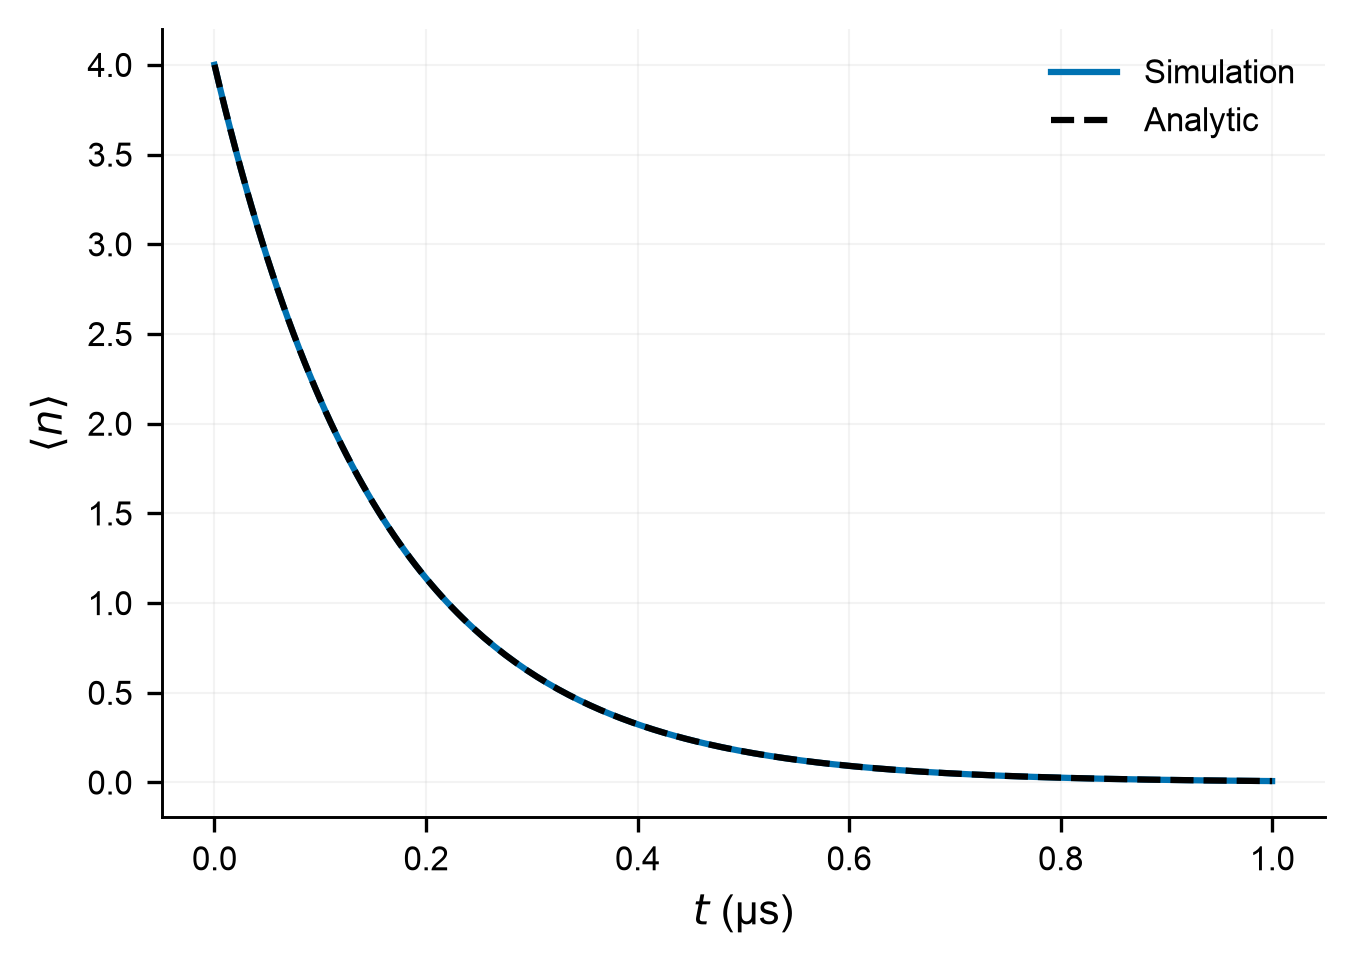

In [3]:
show('task_1_0a_photon_number', 850)

**Single-photon decay.** Mean occupation $\langle n\rangle$ of an initial coherent state $|\alpha_0=2\rangle$. The numerical solution is compared with $|\alpha_0|^2e^{-\kappa t}$ for $\kappa=2\pi\mathrm{\mu s}^{-1}$. The Hamiltonian detuning has the same value and does not affect the occupation. The single-mode cutoff is $N=30$.

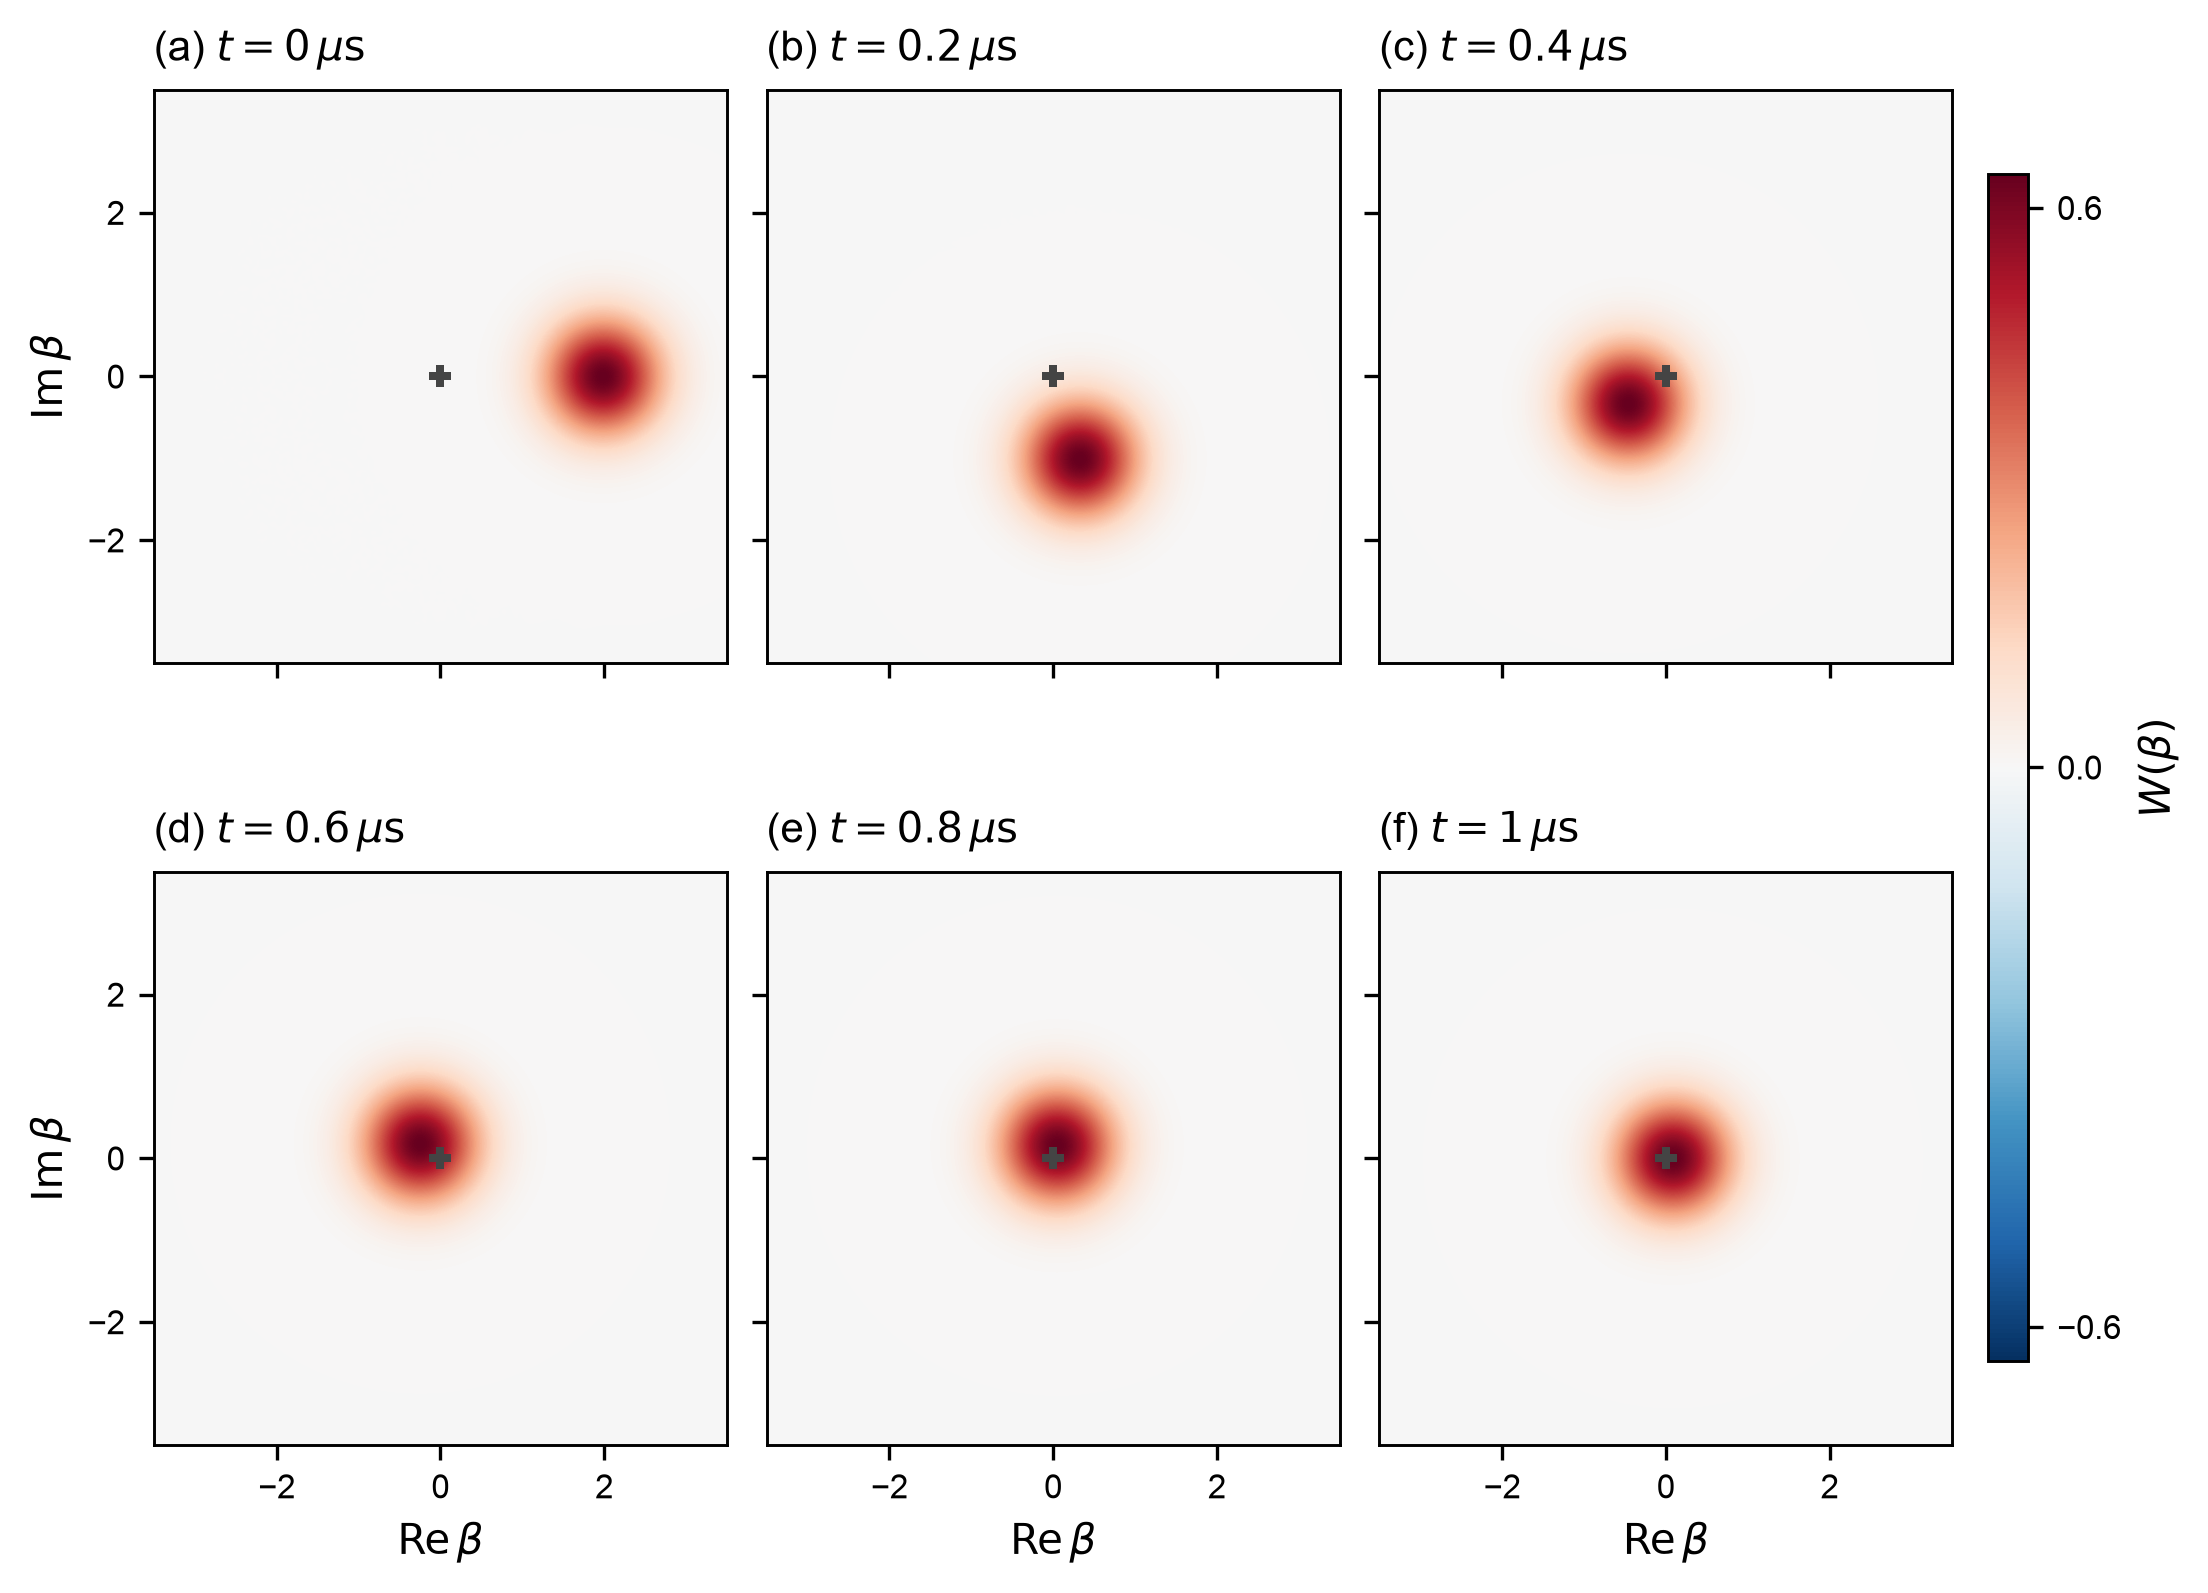

In [4]:
show('task_1_0a_wigner', 950)

**Phase-space evolution under single-photon loss.** Wigner functions of the state in the single-photon decay calculation at the indicated times. The coordinate $\beta$ is the complex phase-space amplitude, so a coherent state $|\alpha\rangle$ is centred at $\beta=\alpha$. All panels share the scale $-2/\pi\leq W\leq2/\pi$, with $\int W(\beta)\mathrm{d}^2\beta=1$.

[Animated evolution](../figures/task_1_0a_wigner.gif)

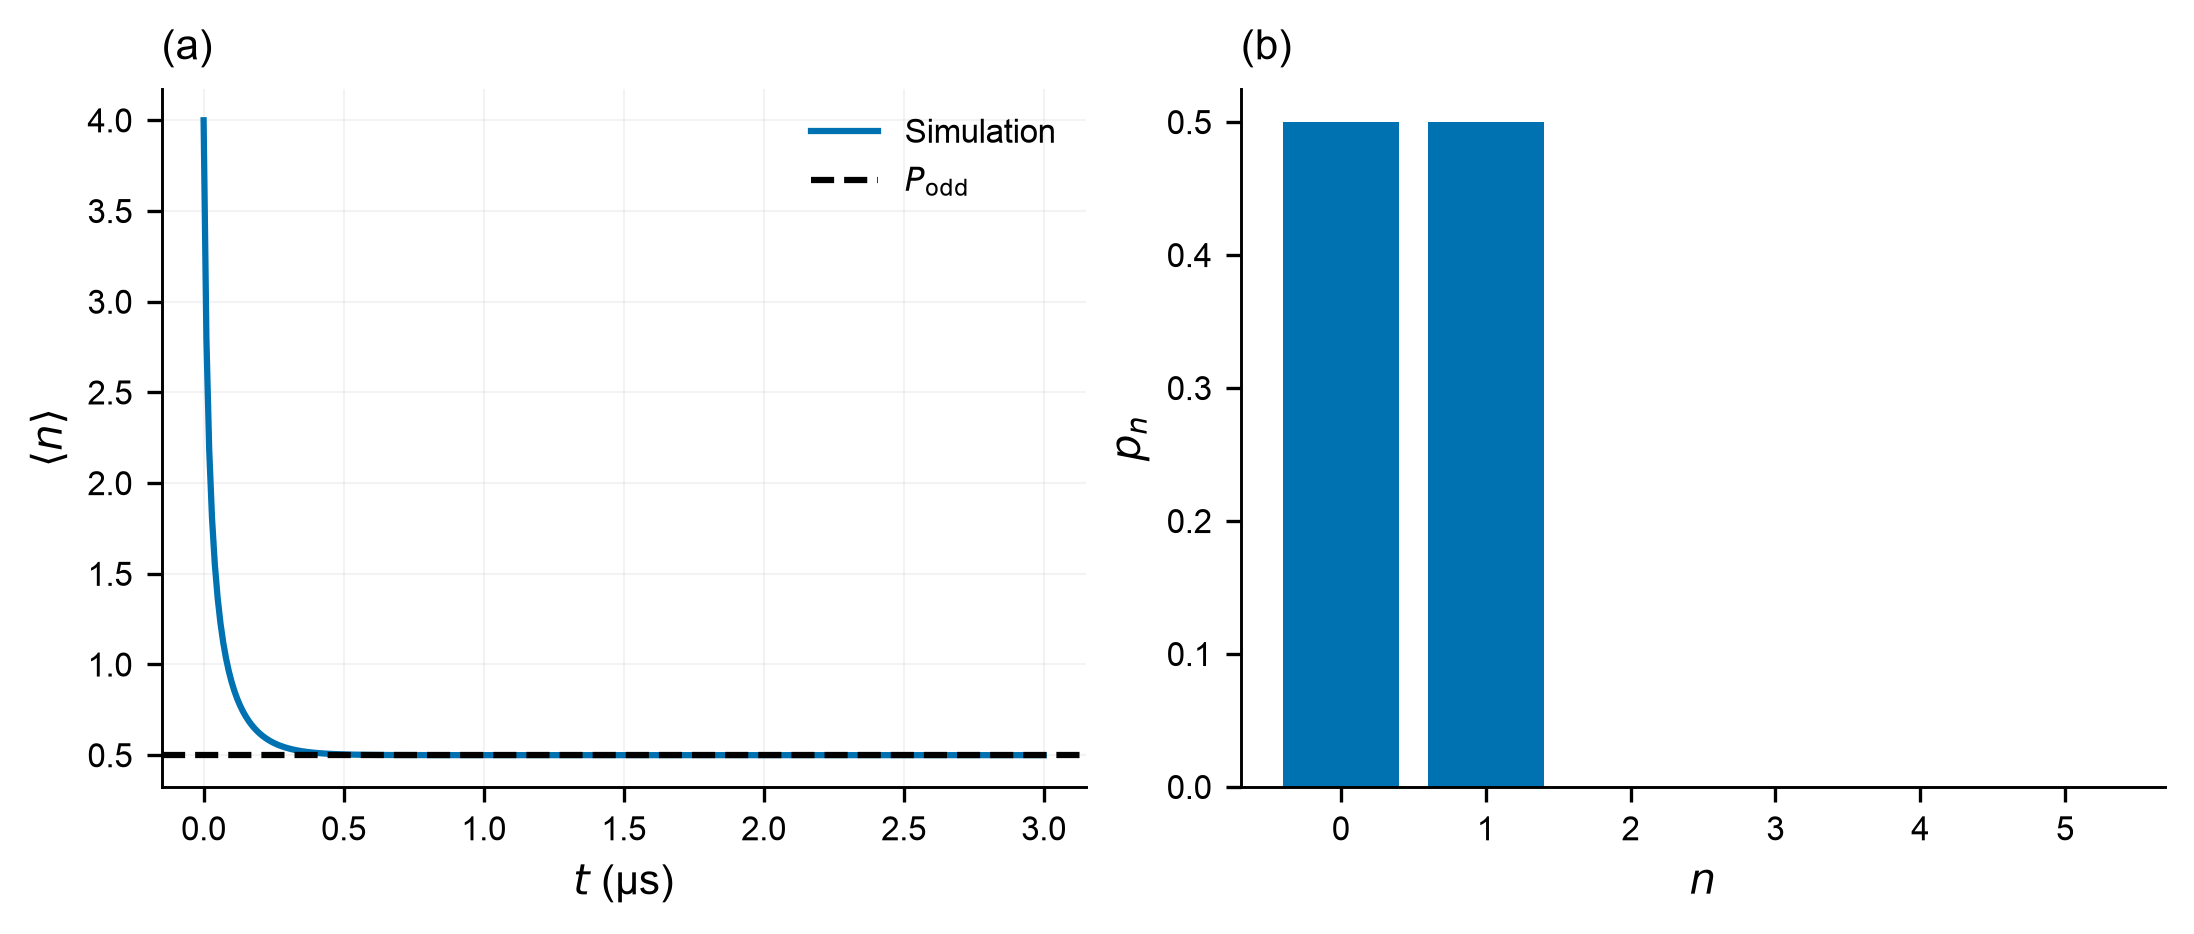

In [5]:
show('task_1_0b_two_photon_loss', 850)

**Parity-preserving two-photon loss.** (a) Mean occupation for an initial coherent state $|\alpha_0\rangle$ with $\alpha_0=2$ under the jump operator $\sqrt{\kappa_2}a^2$. The dashed line is the conserved odd-parity weight $P_{\mathrm{odd}}=(1-e^{-8})/2$, which fixes the asymptotic occupation. (b) Fock probabilities $p_n=\langle n|\rho|n\rangle$ at $t=3$ µs. The cutoff is $N=30$.

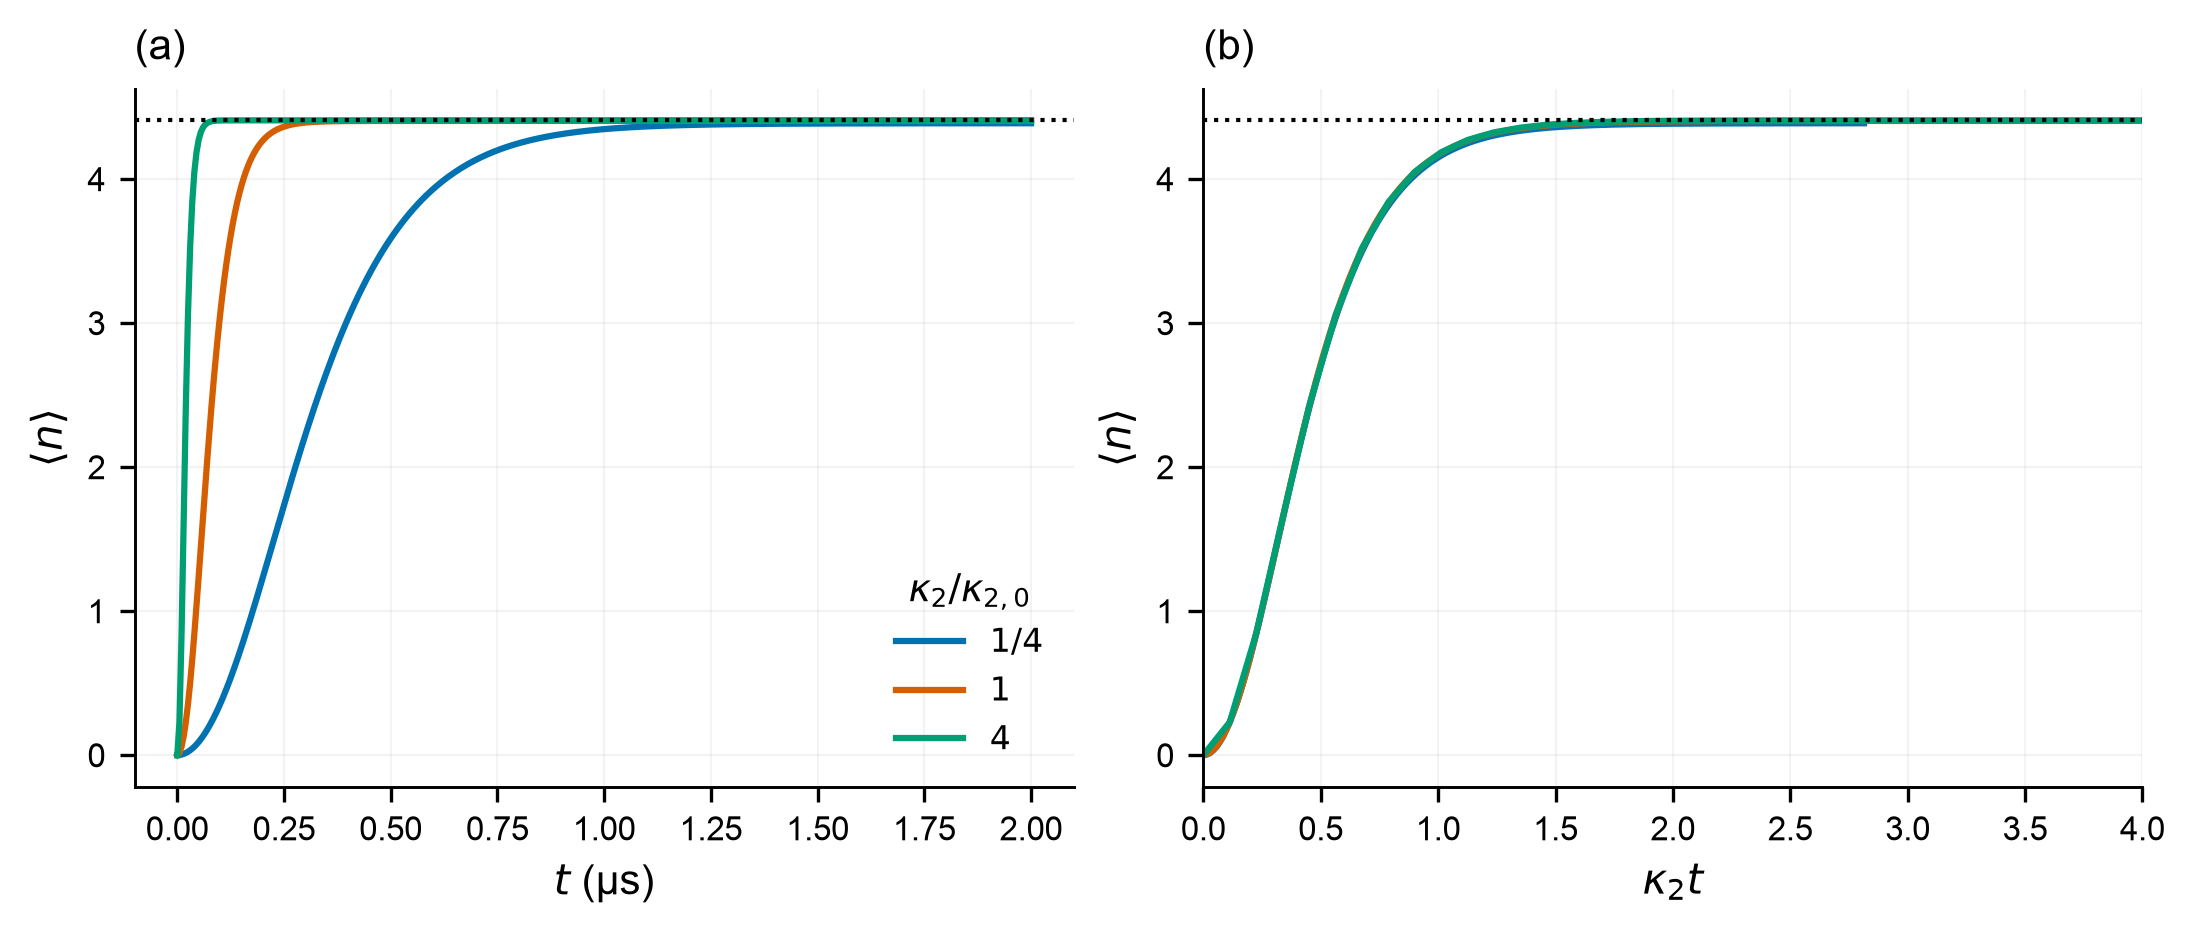

In [6]:
show('task_1_0c_kappa2_sweep', 850)

**Effective two-photon stabilization.** Mean occupation from vacuum, plotted against (a) time and (b) scaled time $\kappa_2t$. Legend values specify $\kappa_2/\kappa_{2,0}$, where $\kappa_{2,0}=4g_2^2/\kappa_b$. The dotted line is $\alpha^2=4.41$. The near collapse in (b) reflects two-photon stabilization; the fixed, nonzero single-photon loss rate prevents exact scaling. The cutoff is $N=30$.

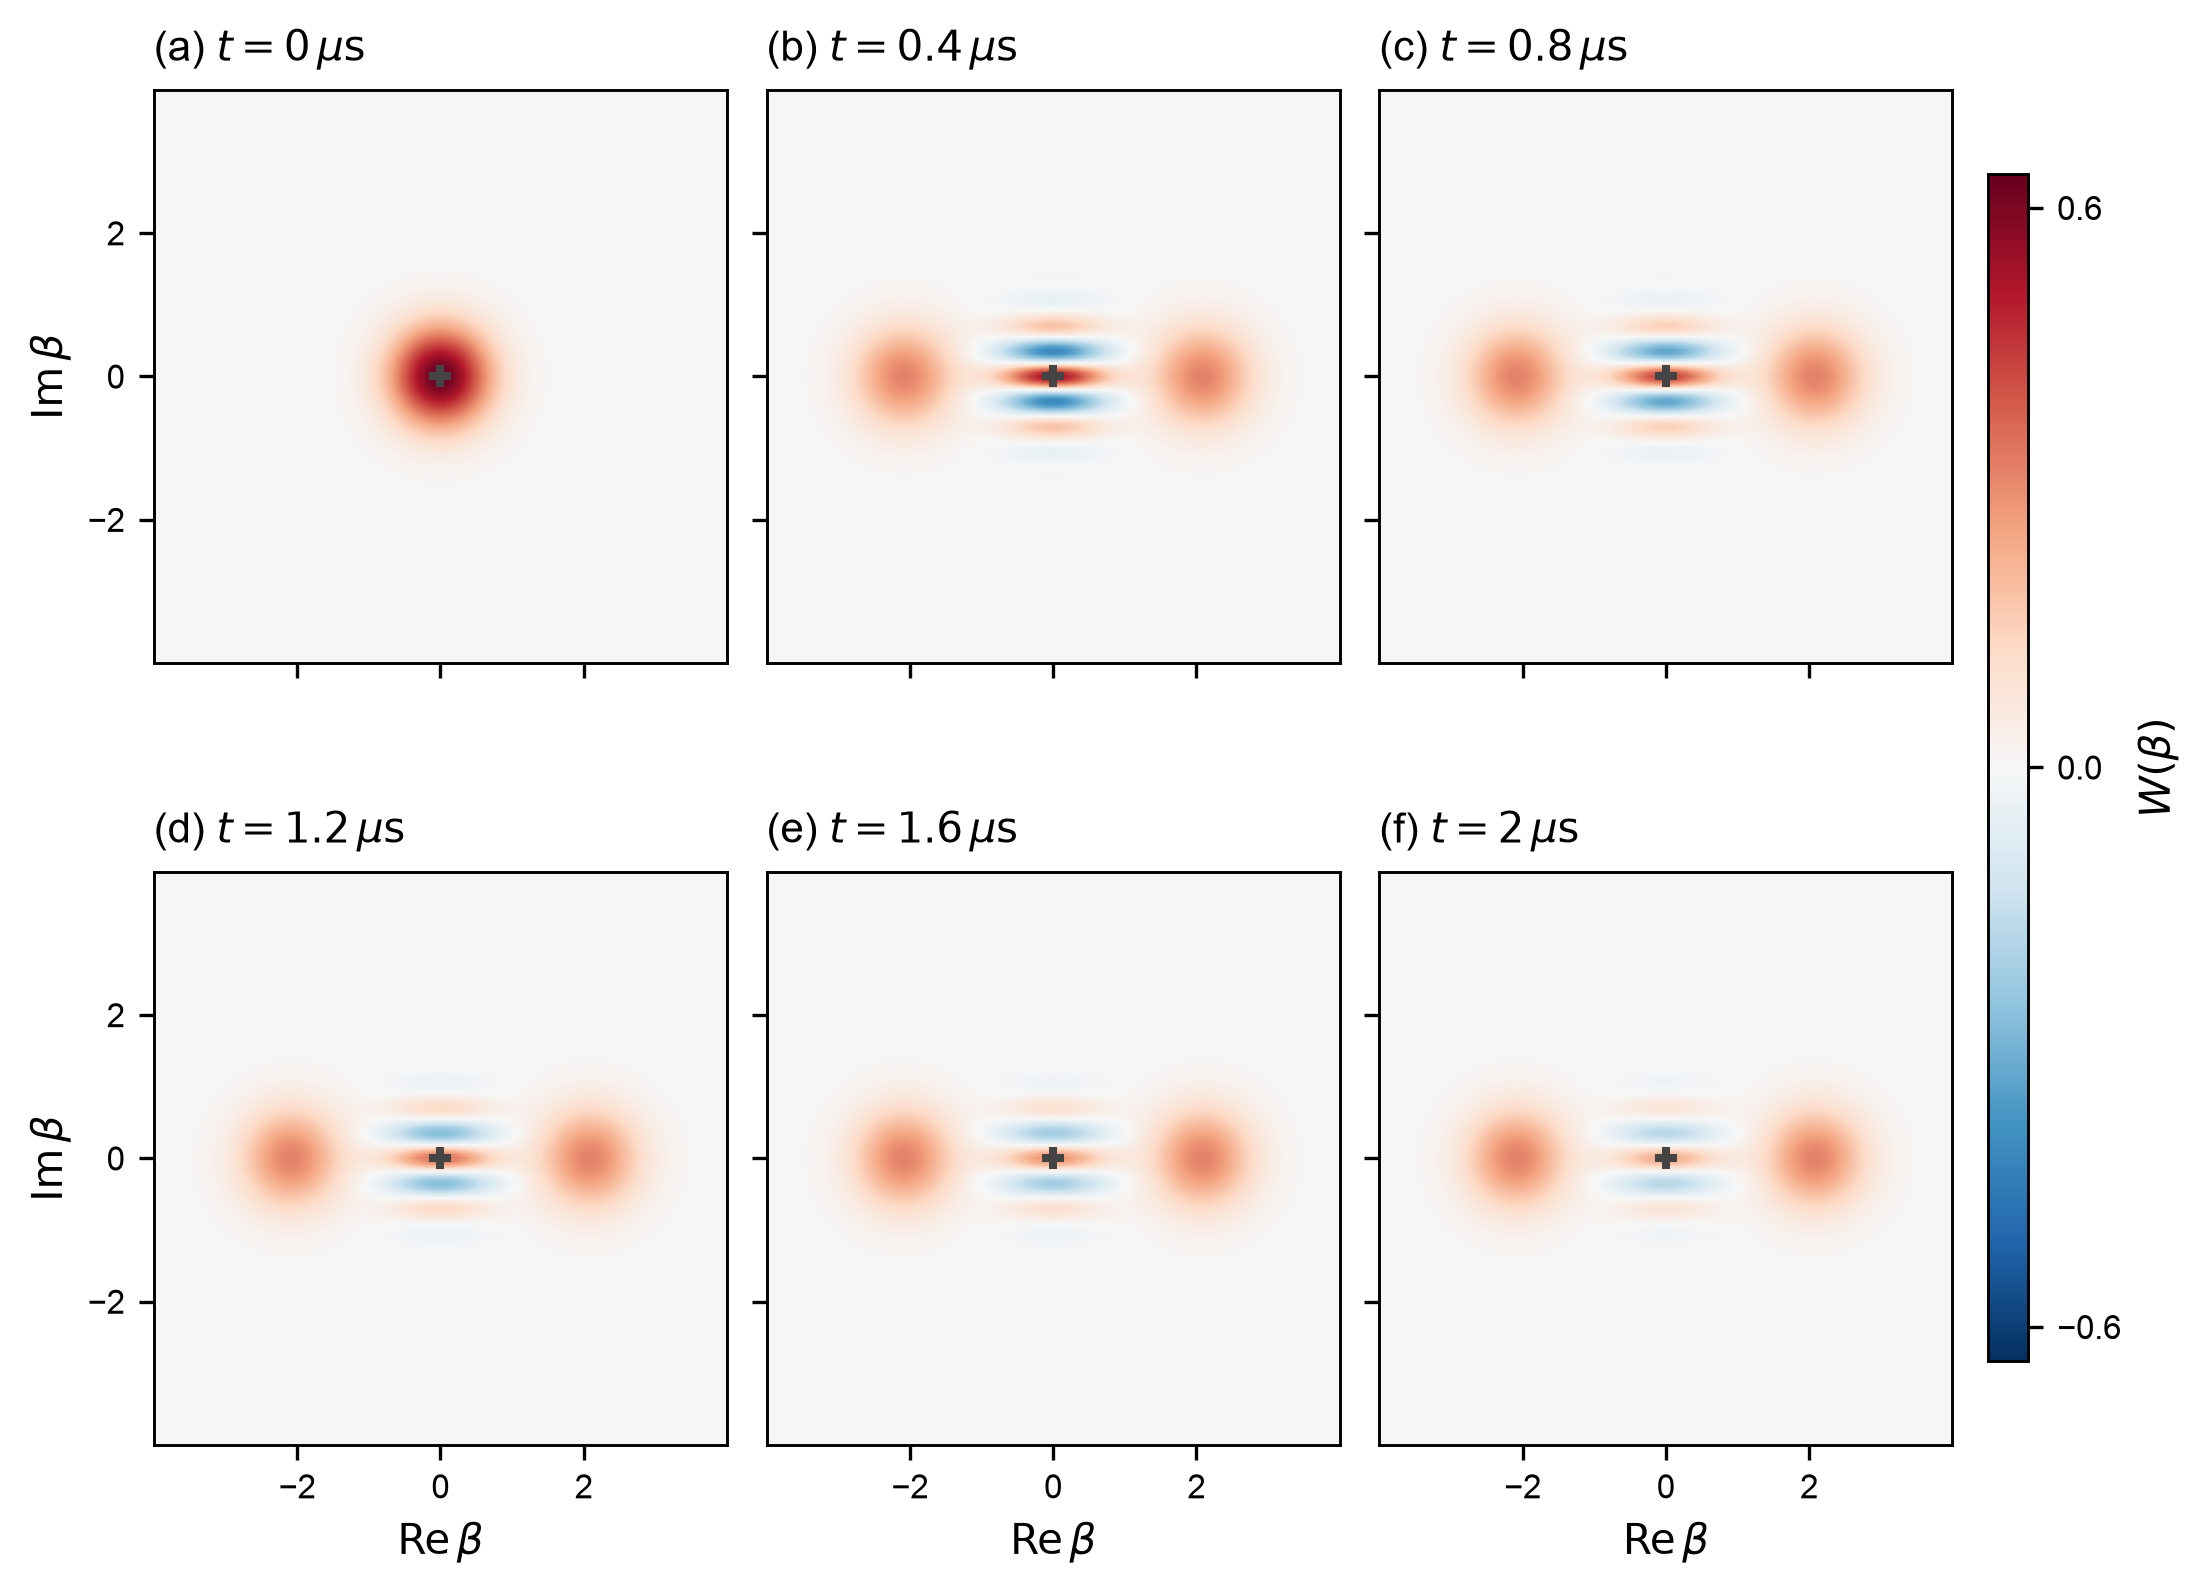

In [7]:
show('task_1_0c_wigner', 950)

**Cat formation in the effective model.** Wigner functions from vacuum at the nominal rate $\kappa_{2,0}$, at the indicated times. The phase-space coordinate is $\beta=\mathrm{Re}(\beta)+i\mathrm{Im}(\beta)$. All panels use the same normalized Wigner convention and color scale, $-2/\pi\leq W\leq2/\pi$; negative values resolve the interference fringes.

[Animated evolution](../figures/task_1_0c_wigner.gif)